# histo2mri demo: registering a section

One call registers one histology section to its MRI:

```python
from histo2mri import register_section
info = register_section(bids_root, subject, sample, out_dir)
```

This notebook runs that call on a NextBrain section and looks at what it wrote: the QC
figures and the transform. Section 5 starts from the raw slide instead, cleaning it with
cleanslide first, which is what `--cleanslide` does on the command line. The steps inside the call are not shown here;
[demo_pipeline_steps.ipynb](demo_pipeline_steps.ipynb) unrolls them.

## 0. Setup

Imports the package from the repository root, so the notebook runs without installing it,
and shows the package's warnings in the notebook output. The full log goes into
`<section>_process.log`.

In [1]:
import logging
import os
import sys

import numpy as np

# Repository root = the parent of notebook/, so `import histo2mri` works uninstalled.
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import histo2mri
from histo2mri import PROFILES, register_section

print("histo2mri", histo2mri.__version__, "from:", os.path.relpath(os.path.dirname(histo2mri.__file__)))
print("profiles :", list(PROFILES))

histo2mri 0.1.0a3 from: ../histo2mri
profiles : ['default', 'he-cblock']


In [2]:
import warnings

# skimage 0.26 deprecates binary_dilation; the call is inside the package, and the warning
# is noise here. Remove this once preprocessing uses morphology.dilation.
warnings.filterwarnings("ignore", message=".*binary_dilation.*")

_pkg_logger = logging.getLogger("histo2mri")
for _h in list(_pkg_logger.handlers):
    _pkg_logger.removeHandler(_h)
_handler = logging.StreamHandler(sys.stdout)
_handler.setFormatter(logging.Formatter("%(levelname)s %(name)s: %(message)s"))
_handler.setLevel(logging.WARNING)   # only warnings; the step lines come from verbose=True
_pkg_logger.addHandler(_handler)
_pkg_logger.setLevel(logging.INFO)
_pkg_logger.propagate = False

## 1. The section

This demo uses one publicly available section:

> **NextBrain** - Iglesias Gonzalez, Casamitjana, Atzeni, Billot, Thomas, Blackburn et al.,
> *Registered histology, MRI, and manual annotations of over 300 brain regions in 5 human
> hemispheres*, University College London, 2023.
> [doi:10.5522/04/24243835.v1](https://doi.org/10.5522/04/24243835.v1), CC0-1.0.
>
> Subject **NB_EX9-19**, block **P2.3**, section **06**, H&E stain.

The data is not shipped with the package; the README describes the BIDS layout it is read
from, in which this section is `sub-NBEX919` / `sample-P2306` / `stain-HE`. Point
`HISTO2MRI_BIDS` at your own dataset, or edit `BIDS_ROOT` below.

In [3]:
BIDS_ROOT = os.environ.get("HISTO2MRI_BIDS", os.path.join("..", "..", "data", "bids"))
SUBJECT = "NBEX919"               # sub-NBEX919  (NextBrain NB_EX9-19)
SAMPLE = "P2306"                  # sample-P2306 (block P2.3, section 06)
STAIN = "HE"                      # optional; needed only when a sample has several stains
OUT_DIR = os.path.join("..", "results", "demo_call_registration_pipeline")

print("BIDS root:", BIDS_ROOT)
print("output   :", OUT_DIR)

BIDS root: ../../data/bids
output   : ../results/demo_call_registration_pipeline


## 2. The call

`register_section` runs the whole registration and writes its outputs into `out_dir`. The
keyword arguments are the defaults of the command line; the two changed here are the ones
NextBrain sections need: `ransac_sample_size=3` because these sections give few matches, and
`mri_on_histo_tile_size=2048` because the histology is 4 um, so the default 348-pixel
checkerboard tile would be invisibly small.

Everything else - the cutting plane, the in-plane rotation, the flip and the pixel size -
comes from the BIDS sidecars, so nothing about the geometry is passed in here. It takes a
few minutes on a GPU; `device="cpu"` works but is much slower. Errors are not caught inside,
so a section that cannot be registered raises here.

[1/19] Load the section and its MRI


[2/19] Histology to MRI spacing


[3/19] Prepare the histology


[4/19] Prepare the MRI slab


[5/19] Find ROI: histology scale


[6/19] Find ROI: patch size, strides and z centre


[7/19] Fine patch matching


[8/19] Outlier filtering


[9/19] ROI plane


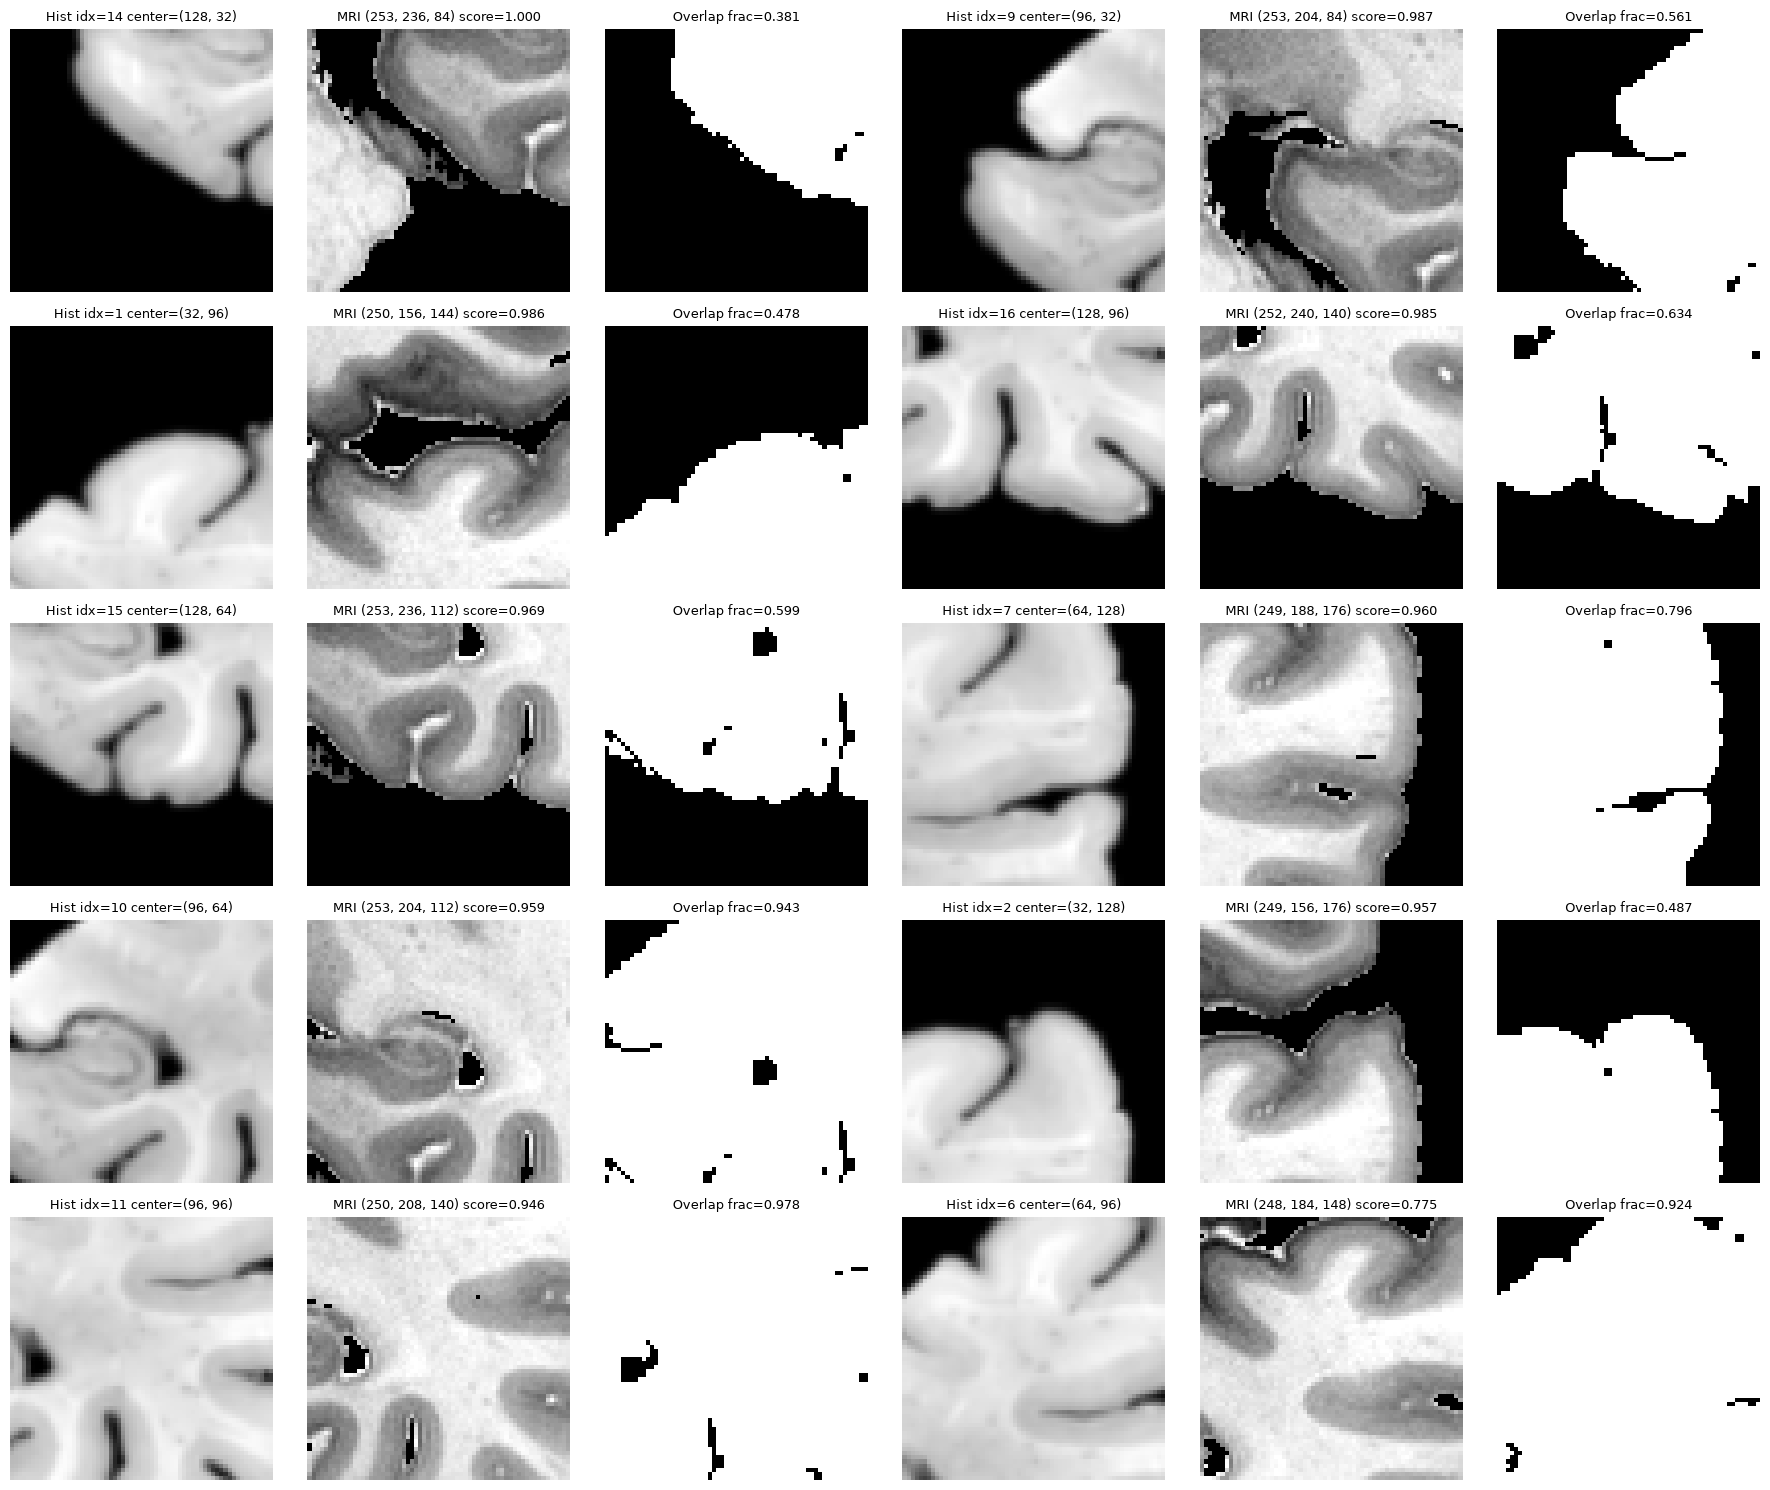

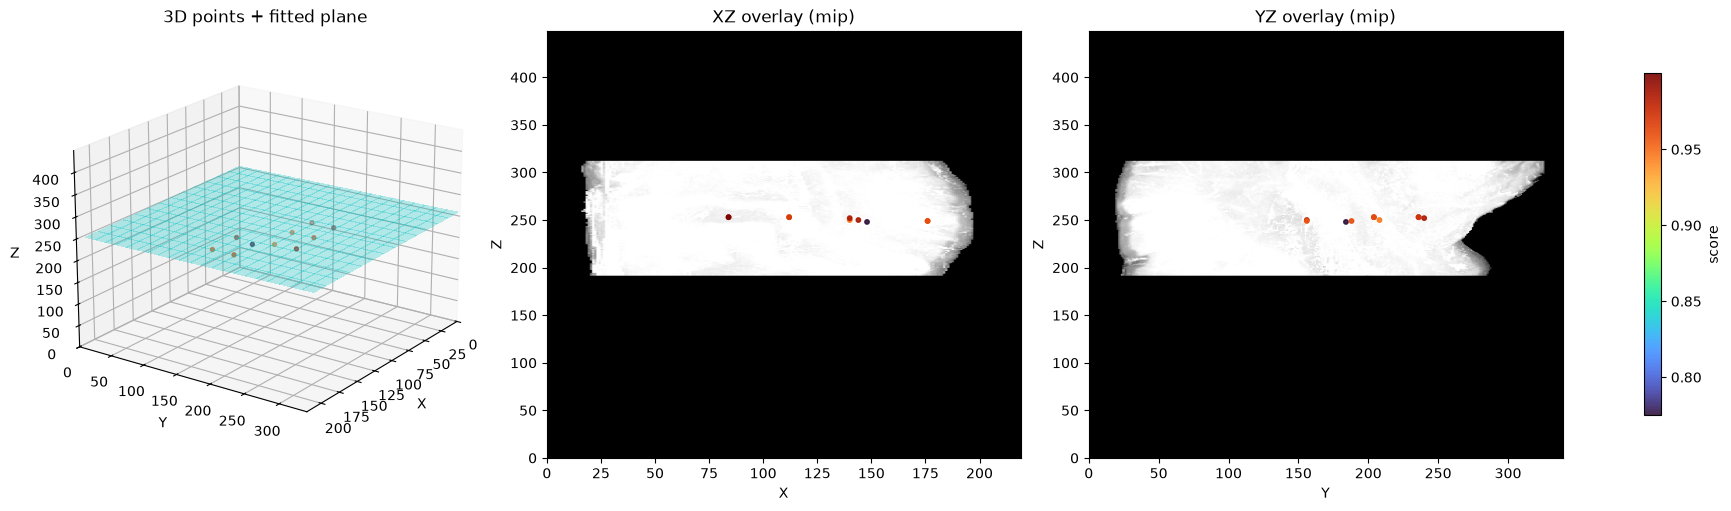

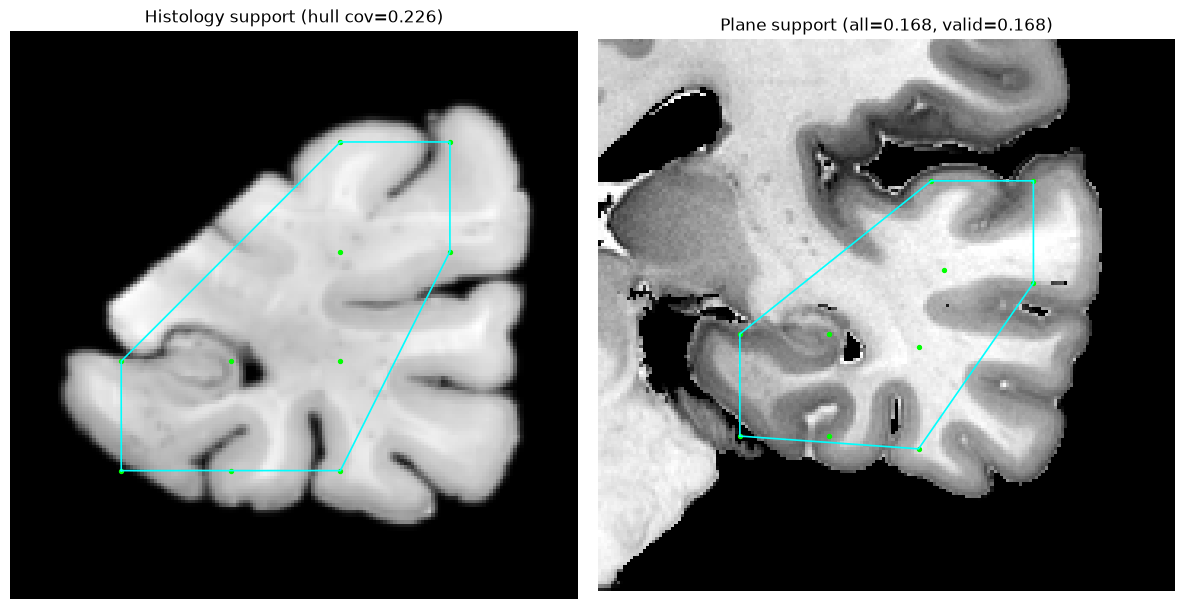

[10/19] Common canvas


[11/19] Global in-plane transform G


[12/19] Robust TPS


WARNING histo2mri.tps: RANSAC TPS: no valid hypothesis found; falling back to all points.


[13/19] Residual TPS on top of G


[14/19] Histology on the initial surface


[15/19] Fold check of the initial sheet


[16/19] Curved-sheet refinement


[17/19] QC figures in MRI space


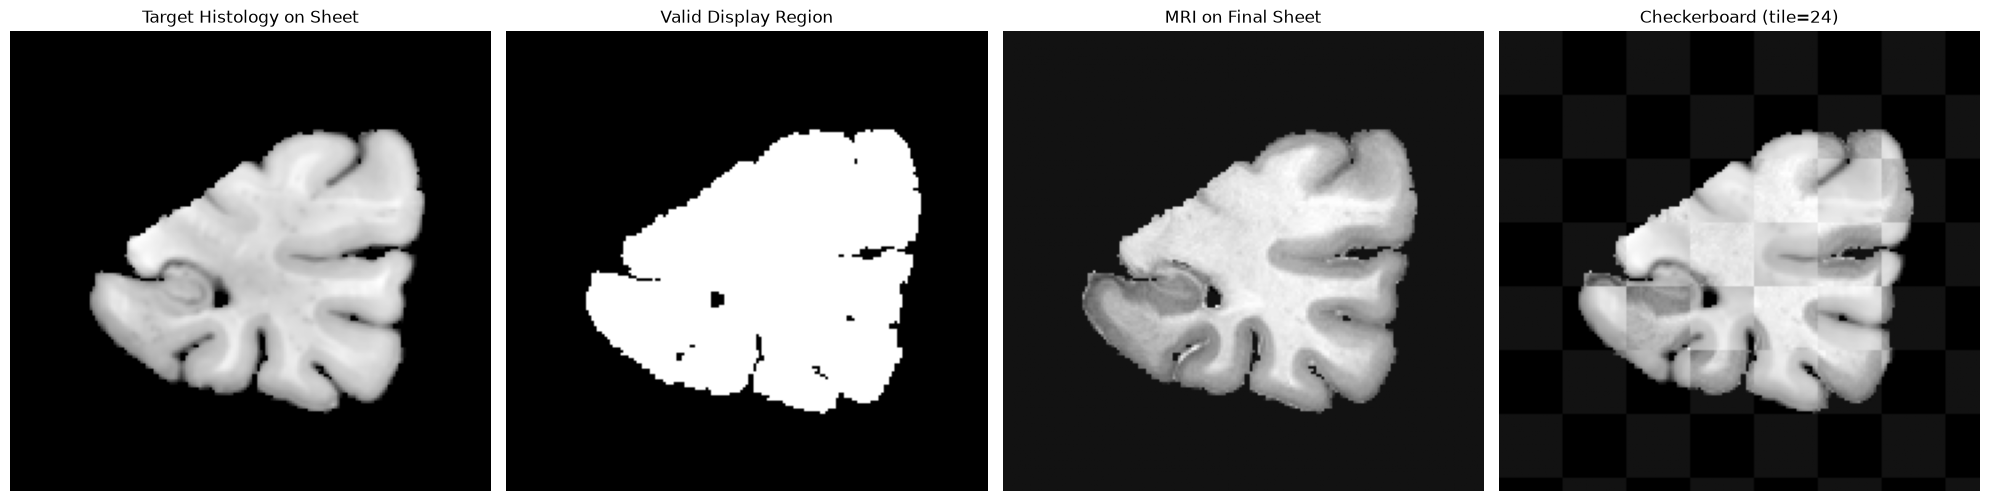

[18/19] Back to HR histology space


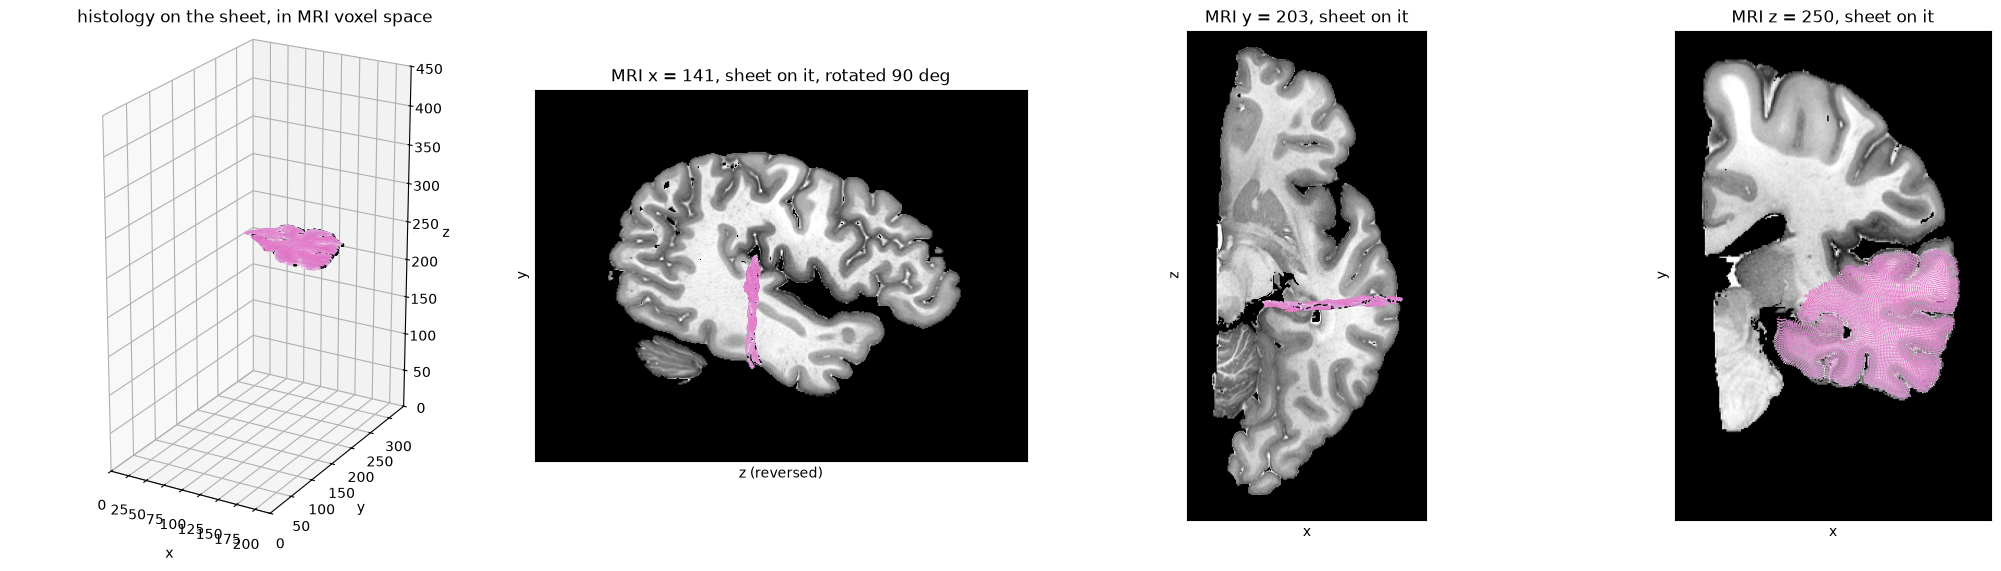

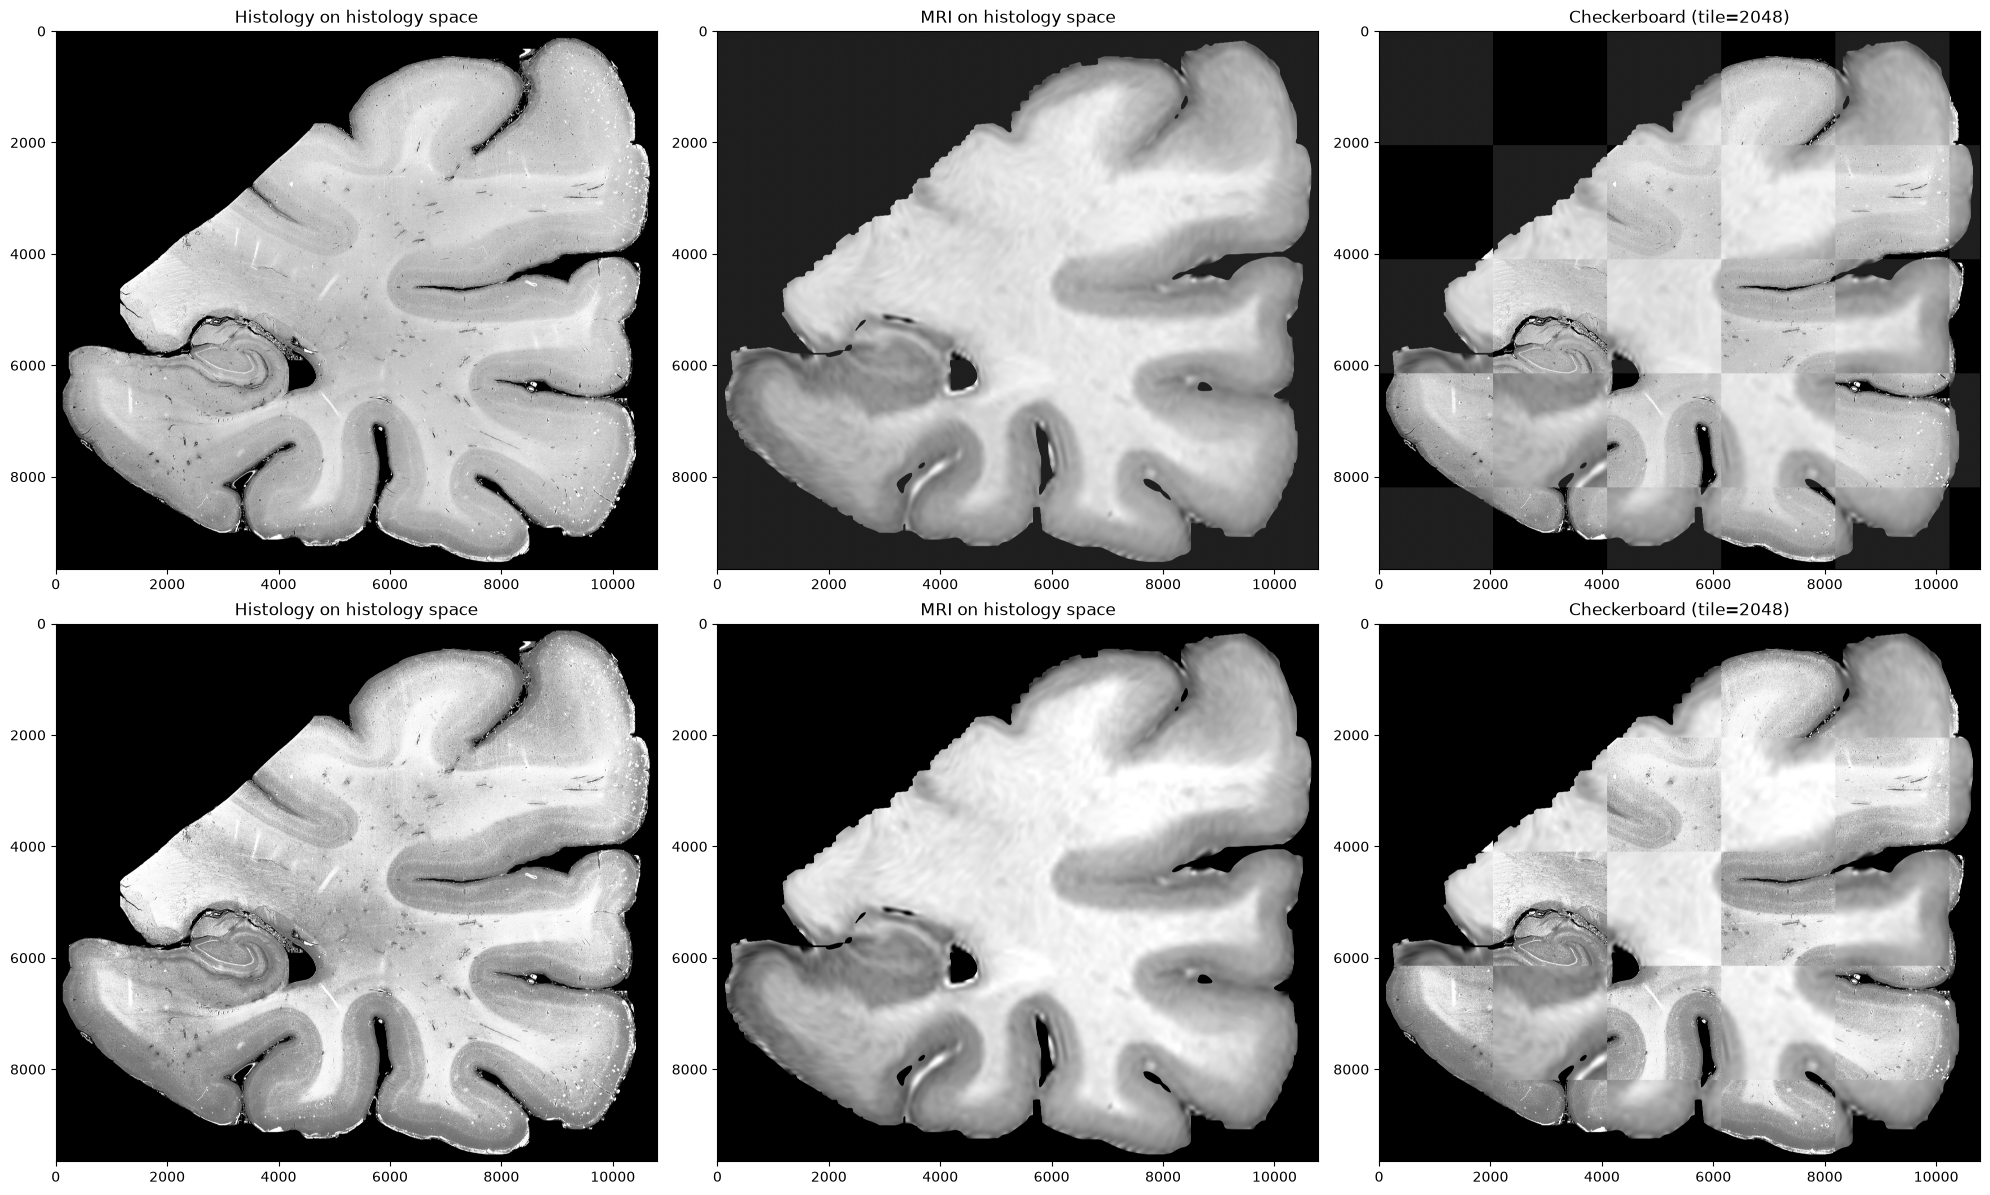

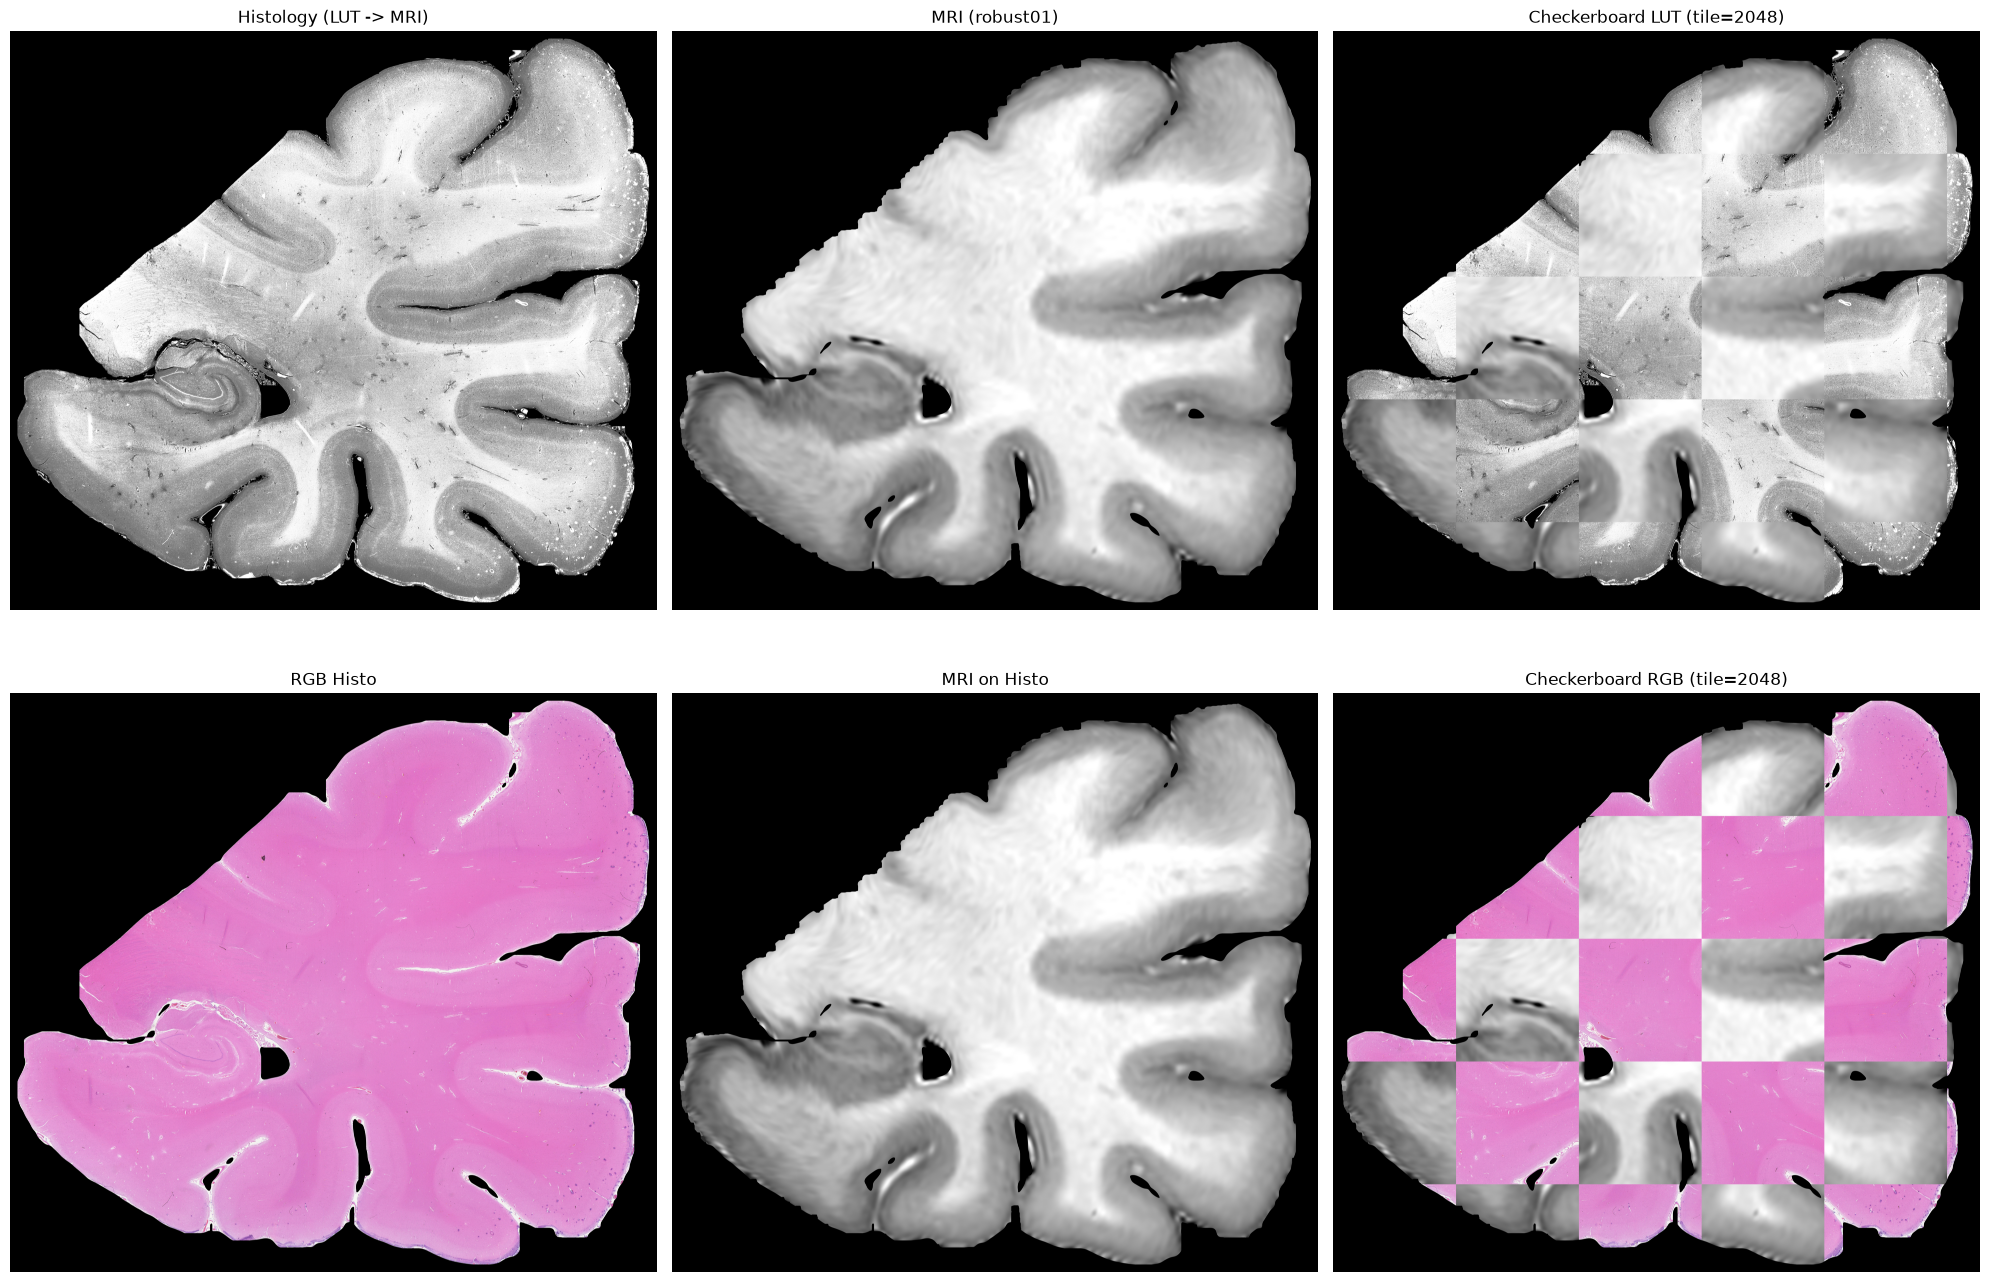

[19/19] Save the transform


{'output_npz': '../results/demo_call_registration_pipeline/sub-NBEX919_sample-P2306_stain-HE_transform_grid.npz',
 'n_clean_matches': 10,
 'best_scale': 1.2999999523162842,
 'profile': 'default',
 'elapsed_sec': 295.6993744308129}

In [4]:
VERBOSE = True   # True: print each step as it starts and show the QC figures; False: silent

info = register_section(
    BIDS_ROOT, SUBJECT, SAMPLE, OUT_DIR,
    stain=STAIN,
    profile="default",            # "he-cblock" for H&E cerebellum blocks
    device=None,                  # None -> cuda:0 when available, else cpu
    ransac_sample_size=3,
    mri_on_histo_tile_size=2048,
    save_roi_qc=True,             # also write the three ROI QC figures
    verbose=VERBOSE,
)
info


## 3. What it wrote

The returned dict names the transform it saved and a few numbers about the run. The same
folder holds the QC figures and this section's log.

In [5]:
for name in sorted(os.listdir(OUT_DIR)):
    size_mb = os.path.getsize(os.path.join(OUT_DIR, name)) / 1e6
    print(f"{size_mb:8.2f} MB  {name}")

    0.04 MB  sub-NBEX919_sample-P2306_stain-HE_histo_in_mri_space.png
    0.14 MB  sub-NBEX919_sample-P2306_stain-HE_histo_in_mri_space_all.png
    0.47 MB  sub-NBEX919_sample-P2306_stain-HE_histo_in_mri_volume.png
    0.69 MB  sub-NBEX919_sample-P2306_stain-HE_mri_on_histo.png
    8.68 MB  sub-NBEX919_sample-P2306_stain-HE_mri_on_histo_all.png
   11.95 MB  sub-NBEX919_sample-P2306_stain-HE_mri_on_histo_rgb.png
    0.00 MB  sub-NBEX919_sample-P2306_stain-HE_process.log
    0.45 MB  sub-NBEX919_sample-P2306_stain-HE_roi_3d.png
    0.38 MB  sub-NBEX919_sample-P2306_stain-HE_roi_pairs.png
    0.16 MB  sub-NBEX919_sample-P2306_stain-HE_roi_support.png
    0.65 MB  sub-NBEX919_sample-P2306_stain-HE_transform_grid.npz


## 4. The transform

`<base>_transform_grid.npz` is the result to keep: it maps a point on the slide to a point in
the volume and back, and carries the frames needed to return to the original slide and the
original MRI, so full-resolution images are regenerated from it rather than stored. The
README documents every field.

In [6]:
grid = np.load(info["output_npz"], allow_pickle=False)
for key in grid.files:
    arr = grid[key]
    print(f"{key:20s} {str(arr.dtype):10s} {arr.shape if arr.ndim else float(arr) if arr.dtype.kind == 'f' else arr}")

A_common_to_hr       float64    (4, 4)
xyz_norm_final       float32    (173, 181, 3)
xy_hist_map          float32    (173, 181, 2)
valid_surf           uint8      (173, 181)
ox_h                 float64    7.0
oy_h                 float64    3.0
G_e1                 float64    (3,)
G_e2                 float64    (3,)
mri_spacing          float64    (3,)
mri_size             int64      (3,)
mri_origin           float64    (3,)
mri_direction        float64    (9,)
mri_permute          int64      (3,)
mri_view_flip        bool       (3,)
mri_orientation      <U7        coronal
mri_canonical        <U3        LPS
mri_source           <U55       ../../data/bids/sub-NBEX919/anat/sub-NBEX919_T1w.nii.gz
histo_on_surface     float32    (173, 181)
mri_on_surface       float32    (173, 181)
A_hr_to_tif          float64    (4, 4)
crop_origin_xy       int64      (2,)
source_shape_hw      int64      (2,)
histo_source         <U107      ../../data/bids/derivatives/cleanslide/sub-NBEX919/micr/sub-NBE

## 5. Starting from a raw slide: cleaning with cleanslide

`register_section` reads a section that is already cleaned: an inverted grayscale with the
background at 0, plus its tissue mask. If the histology is not cleaned yet,
[cleanslide](https://github.com/spittayapong/cleanslide) makes those from the raw brightfield
slide (`pip install "histo2mri[cleanslide]"`). `clean_file` runs it on one raw slide and
writes the cleaned image, mask, colour image, sidecar and cleanslide's QC panels;
`register_files` then registers those files.

`register_files` takes explicit files rather than a BIDS dataset, so what the sidecars would
say is passed in. These are the values of this section's sidecar: coronal, no rotation, flip
`x`, 4 um pixels and a background threshold of 235. Together the two calls are what
`histo2mri register --cleanslide` runs. Look at the `qc_stages` panel before trusting the
result: a bad clean does not fail, it shows up as a bad registration.

In [7]:
from histo2mri import register_files
from histo2mri.clean import clean_file

BASE = f"sub-{SUBJECT}_sample-{SAMPLE}_stain-{STAIN}"
RAW_SLIDE = os.path.join(BIDS_ROOT, f"sub-{SUBJECT}", "micr", f"{BASE}_BF.tif")
MRI = os.path.join(BIDS_ROOT, f"sub-{SUBJECT}", "anat", f"sub-{SUBJECT}_T1w.nii.gz")
MRI_MASK = os.path.join(BIDS_ROOT, "derivatives", "brainmask", f"sub-{SUBJECT}", "anat",
                        f"sub-{SUBJECT}_desc-brain_mask.nii.gz")
CLEAN_OUT_DIR = os.path.join("..", "results", "demo_call_registration_pipeline_cleanslide")

cleaned = clean_file(RAW_SLIDE, pixel_size_um=4.0, out_dir=CLEAN_OUT_DIR, prefix=BASE,
                     background_threshold=235)
for key, value in cleaned.items():
    print(f"{key:11s} {os.path.basename(value) if isinstance(value, str) else value}")

histo_gray  sub-NBEX919_sample-P2306_stain-HE_desc-clean_BF.tif
histo_mask  sub-NBEX919_sample-P2306_stain-HE_desc-tissue_mask.tif
histo_rgb   sub-NBEX919_sample-P2306_stain-HE_desc-cleanrgb_BF.tif
sidecar     sub-NBEX919_sample-P2306_stain-HE_desc-clean_BF.json
qc_outputs  sub-NBEX919_sample-P2306_stain-HE_cleanslide_outputs.png
qc_stages   sub-NBEX919_sample-P2306_stain-HE_cleanslide_qc.png
crop        {'crop_origin_xy': (2562, 693), 'source_shape_hw': (11861, 14630)}


In [8]:
info_clean = register_files(
    cleaned["histo_gray"], cleaned["histo_mask"], MRI, MRI_MASK, CLEAN_OUT_DIR,
    orientation="coronal", pixel_size_um=4.0, rotation=0, flip="x",
    histo_rgb=cleaned["histo_rgb"],
    crop=cleaned["crop"],         # where the cleaned image sits in the raw slide
    section_id=BASE,
    device=None, ransac_sample_size=3, mri_on_histo_tile_size=2048,
    verbose=False,                # silent: the figures are saved, not shown
)
info_clean

WARNING histo2mri.tps: RANSAC TPS: no valid hypothesis found; falling back to all points.


{'output_npz': '../results/demo_call_registration_pipeline_cleanslide/sub-NBEX919_sample-P2306_stain-HE_transform_grid.npz',
 'n_clean_matches': 10,
 'best_scale': 1.2999999523162842,
 'profile': 'default',
 'elapsed_sec': 547.0228920159861}

The raw slide went through the same cleaning as the dataset's cleaned section, so the two
calls should agree. The transform from the raw slide also records cleanslide's crop, which is
what maps a result back onto the raw slide.

In [9]:
with np.load(info["output_npz"]) as a, np.load(info_clean["output_npz"]) as b:
    print("largest sheet difference (normalised):", np.abs(a["xyz_norm_final"] - b["xyz_norm_final"]).max())
    print("crop origin in the raw slide (x, y)   :", b["crop_origin_xy"], "of", b["source_shape_hw"], "(h, w)")

largest sheet difference (normalised): 0.0
crop origin in the raw slide (x, y)   : [2562  693] of [11861 14630] (h, w)


## 6. The same from the command line

The command line has two subcommands. `bids` is a BIDS App, so the whole dataset, or any
subset of it, runs without Python:

```bash
histo2mri bids /path/to/bids /path/to/derivatives/histo2mri participant \
    --participant-label NBEX919 --sample-label P2306 --stain-label HE \
    --ransac-sample-size 3 --mri-on-histo-tile-size 2048
```

It writes the same per-section files, but into `<output_dir>/<sub>/<base>/` and with a
`dataset_description.json` at the root, whereas `register_section` writes straight into the
`out_dir` it is given. Add `--cleanslide` to start from the raw `sub-X/micr/*_BF.tif` sections:
they are cleaned into `<output_dir>/cleanslide/` and registered from there, and the input
dataset is only read.

`register` takes one section as explicit files, like section 5. With `--cleanslide`, `--histo`
is the raw slide and the mask is made for you:

```bash
histo2mri register --cleanslide --cleanslide-background-threshold 235 \
    --histo sub-NBEX919_sample-P2306_stain-HE_BF.tif \
    --mri sub-NBEX919_T1w.nii.gz --mri-mask sub-NBEX919_desc-brain_mask.nii.gz \
    --orientation coronal --histo-pixel-size 4 --flip x \
    --ransac-sample-size 3 --mri-on-histo-tile-size 2048 \
    -o out/sub-NBEX919_sample-P2306_stain-HE
```